# Solar filament instance segmentation — end-to-end pipeline

This notebook contains the whole pipeline: pre-processing, training (optional), segmentation, post-processing (instance candidates and selection) and evaluation. By default it does not retrain: it loads the trained weights stored in this repository (`weights/ens1536`), walks through every stage on one image, runs the same code on the whole test folder, writes `submission.csv` (one row per filament: `filament_id`, `segmentation_rle`) and finally evaluates the pipeline out-of-fold on the training images.

**Stages**
1. Pre-processing: standardise the image by its on-disk pixels.
2. Training (optional, `TRAIN = True`): retrain all models from the competition training data and build a new bundle.
3. Load and verify the model bundle.
4. Segmentation: 10 U-Nets (EfficientNetV2-S and -M, 5 folds each), D4 test-time augmentation, averaged probability map.
5. Instance candidates: p > 0.4; fragments in the same connected component of p > 0.15 form one instance (saddle linking); area ≥ 100 px.
6. Selection: each candidate's expected PQ contribution is predicted by LightGBM (20 features) and a ResNet-18 on a 160×160 crop (3 seeds); keep if 0.5·LightGBM + 0.5·CNN > 0.25.
7. All test images → disjoint COCO RLE masks.
8. Inspect the result.
9. Evaluation on the training images with the competition metric (out-of-fold).

**Requirements:** CUDA GPU with ≥ 12 GB memory, `pip install -r requirements.txt`, competition data in `MAGFiLO_1.0_Kaggle_2026/`. Runtime on an RTX 3090 Ti: ~6 s per test image (~17 min for the 180 test images), ~25 min for the evaluation, ~17 h for the optional retraining. Inference uses only the images in `IMAGES`.

In [1]:
import os, sys, time, warnings
warnings.filterwarnings('ignore', message='IProgress not found')  # tqdm without ipywidgets
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from data import read_image
from train import normalize
from scorer import CAND
from infer import load_bundle, ensemble_prob, score_candidates, keep_instances, predict_folder

def overlay(img, lab, colors):
    """Draws label masks over a grayscale image; colors maps label -> RGB."""
    out = np.repeat(img[..., None], 3, axis=2).astype(np.float32)
    for k, c in colors.items():
        m = lab == k
        out[m] = 0.45 * out[m] + 0.55 * np.asarray(c, np.float32)
    return out.astype(np.uint8)

## Settings
`IMAGES`: folder of 2048×2048 GONG H-alpha JPEG images to segment (the competition test folder by default). `EXAMPLE`: index of the image used for the step-by-step walk-through. `TRAIN`: retrain everything instead of loading the stored weights. `EVALUATE`: run the out-of-fold evaluation of section 9 (`EVAL_PER_FOLD` limits it to the first n images of each fold for a quick check; `None` = all 707).

In [2]:
IMAGES = 'MAGFiLO_1.0_Kaggle_2026/test/test_images'
OUT = 'submission.csv'
BUNDLE = 'weights/ens1536'
EXAMPLE = 21
TRAIN = False
EVALUATE = True
EVAL_PER_FOLD = None

## 1. Pre-processing
Stations differ in brightness and contrast. Each image is standardised by the mean and standard deviation of its on-disk pixels (intensity > 30); no other filtering is applied.

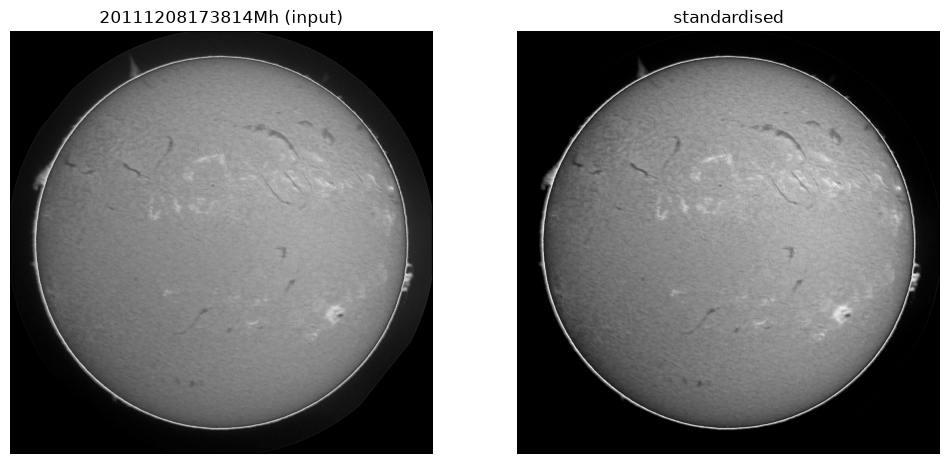

In [3]:
paths = sorted(Path(IMAGES).glob('*.jp*g'))
path = paths[EXAMPLE]
img = read_image(path)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img, cmap='gray'); ax[0].set_title(f'{path.stem} (input)')
ax[1].imshow(normalize(img), cmap='gray', vmin=-3, vmax=3); ax[1].set_title('standardised')
for a in ax: a.axis('off')

## 2. Training (optional)
Skipped by default (`TRAIN = False`): the trained weights in `weights/ens1536` are loaded in section 3. With `TRAIN = True` the cell below runs the same scripts that produced the stored bundle and then uses the new one (`weights/retrained`):
1. **Segmentation models.** U-Net with an EfficientNetV2-S and an EfficientNetV2-M encoder (ImageNet initialisation), 5 folds each, on random 1536 px crops; the target is the pixel-wise mean of the annotators' masks; BCE + Dice loss, AdamW, lr 2e-4, 40 epochs; flips, 90° rotations, affine and brightness/contrast/gamma augmentation (`src/train.py`, `src/augment.py`). The checkpoint with the best validation PQ is kept. The 5 folds are fixed (`outputs/folds.csv`, stratified by station and annotator count, seed 42).
2. **Out-of-fold probability maps.** Every training image is predicted (D4 TTA) only by the fold model that did not train on it, and the two encoders are averaged (`src/oof.py`).
3. **Selectors.** Candidates are cut from the out-of-fold maps and labelled with their PQ contribution. LightGBM (`src/scorer.py`) and the CNN (`src/cnn_selector.py`, 3 seeds) are first trained with nested cross-validation, which prints the unbiased out-of-fold PQ of the full system, and then once on all candidates for inference.
4. **Bundle.** fp16 weights, selectors and thresholds are packed with a SHA-256 manifest (`src/infer.py export`).

In [4]:
if TRAIN:
    import re, subprocess
    env = {**os.environ, 'PYTHONPATH': str(ROOT / 'src')}

    def sh(*args):
        """Runs a pipeline script from the repository root, streams and returns its output."""
        p = subprocess.Popen([sys.executable, *map(str, args)], cwd=ROOT, env=env, text=True,
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
        lines = []
        for line in p.stdout:
            lines.append(line)
            print(line, end='')
        if p.wait():
            raise RuntimeError(f'{args[0]} failed')
        return ''.join(lines)

    MEMBERS = {'retrain_effv2s': 'tu-tf_efficientnetv2_s', 'retrain_effv2m': 'tu-tf_efficientnetv2_m'}
    ENS = ROOT / 'outputs/oof/retrain_ens_tta2'
    # 1. segmentation models (~1.6 h per model and fold on an RTX 3090 Ti)
    for f in range(5):
        for name, enc in MEMBERS.items():
            sh('src/train.py', '--fold', f, '--name', name, '--encoder', enc, '--target', 'mean',
               '--crop', 1536, '--bs', 2, '--lr', 2e-4, '--workers', 10)
    # 2. out-of-fold maps per encoder, then the encoder average
    for name in MEMBERS:
        sh('src/oof.py', '--runs', f'outputs/{name}', '--tta', 2, '--out', f'outputs/oof/{name}_tta2')
    for f in range(5):
        out = ENS / f'fold{f}' / 'val_probs'
        out.mkdir(parents=True, exist_ok=True)
        for p in sorted((ROOT / f'outputs/oof/{next(iter(MEMBERS))}_tta2/fold{f}/val_probs').glob('*.npy')):
            m = sum(np.load(ROOT / f'outputs/oof/{n}_tta2/fold{f}/val_probs/{p.name}').astype(np.float32)
                    for n in MEMBERS) / len(MEMBERS)
            np.save(out / p.name, np.round(m).astype(np.uint8))
    # 3. selectors: nested CV (out-of-fold PQ), then the final models
    log = sh('src/scorer.py', ENS, '--link_thr', 0.15)
    cut = float(re.search(r'kesme: ([\d.]+)', log).group(1))  # best LightGBM-only cut
    for s in range(3):
        sh('src/cnn_selector.py', '--oof', ENS, '--seed', s)
    sh('src/cnn_selector.py', '--oof', ENS, '--final', 3, '--mix', 0.5, '--cut', 0.25,
       '--test_probs', ENS / 'no_test_probs')  # trains the final CNNs only; the test set is predicted below
    # 4. bundle
    sh('src/infer.py', 'export', '--runs', *[f'outputs/{n}' for n in MEMBERS], '--scorer', ENS / 'scorer.txt',
       '--cut', cut, '--link_thr', 0.15, '--cnn', ENS / 'cnn_selector', '--cnn_mix', 0.5, '--cnn_cut', 0.25,
       '--dst', 'weights/retrained')
    BUNDLE = 'weights/retrained'
else:
    print(f'TRAIN = False: using the trained weights in {BUNDLE}')

TRAIN = False: using the trained weights in weights/ens1536


## 3. Model bundle
The 808 MB bundle holds 10 segmentation models (fp16), the LightGBM selector, 3 CNN selector seeds and `config.json` with the thresholds. Files above 50 MB are split into 45 MB parts (`best.pt.part00`, …) to stay under GitHub's file size limit and are joined in memory when loaded. Every file is checked against the SHA-256 in `MANIFEST.json` before anything is loaded. With `TRAIN = True` the bundle built in section 2 is loaded instead.

In [5]:
t0 = time.time()
cfg, groups, scorer, cnns = load_bundle(BUNDLE)
print(f'loaded {sum(map(len, groups))} U-Nets, LightGBM, {len(cnns)} CNNs in {time.time() - t0:.1f} s')
print({k: v for k, v in cfg.items() if k not in ('runs', 'cnn')})

bundle verified: 25 files


loaded 10 U-Nets, LightGBM, 3 CNNs in 6.0 s
{'cut': 0.24, 'link_thr': 0.15, 'tta': 2, 'cnn_mix': 0.5, 'cnn_cut': 0.25}


## 4. Segmentation ensemble
Each U-Net predicts the image and its 8 flips/transposes (D4 TTA); the maps are averaged over the 5 folds of each encoder and then over the two encoders. The networks were trained on the pixel-wise mean of the annotators' masks, so the probability reflects how many annotators would mark a pixel.

7.2 s


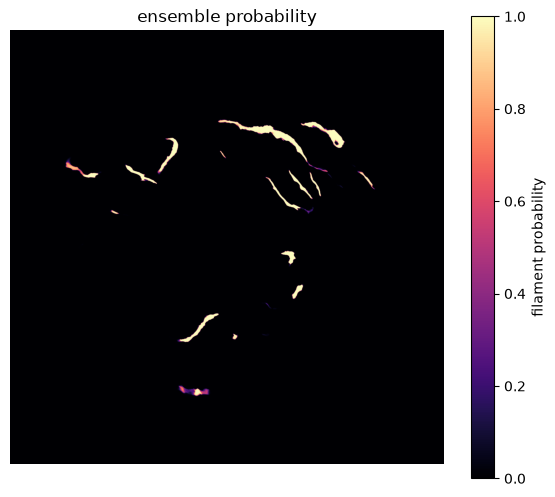

In [6]:
t0 = time.time()
prob = ensemble_prob(img, groups, cfg['tta'])
print(f'{time.time() - t0:.1f} s')
plt.figure(figsize=(7, 6)); plt.imshow(prob, cmap='magma', vmin=0, vmax=1); plt.colorbar(label='filament probability')
plt.axis('off'); plt.title('ensemble probability');

## 5. Instance candidates and 6. selection
Candidates are connected regions of p > 0.4; fragments that are connected through p > 0.15 (a weak probability ridge) are grouped into one instance. For every candidate, LightGBM (shape, probability and contrast features) and the CNN (image, probability and mask crop) predict its expected PQ contribution. Adding a candidate raises PQ only when this contribution exceeds about PQ/2, which is why the cut is 0.25.

candidate settings: {'thr': 0.4, 'min_area': 100, 'join': 0, 'thr_high': None, 'link_thr': 0.15}
16 candidates, 12 kept


,inst,area,p_mean,lgb,cnn,score
11,12,1829,0.964,0.647,0.697,0.672
6,7,1690,0.956,0.661,0.634,0.647
9,10,2227,0.953,0.649,0.644,0.647
0,1,10125,0.943,0.606,0.605,0.605
13,14,3663,0.951,0.565,0.635,0.600
5,6,2244,0.954,0.618,0.544,0.581
12,13,1411,0.954,0.533,0.614,0.574
1,2,5860,0.949,0.511,0.615,0.563
8,9,950,0.933,0.480,0.542,0.511
2,3,3466,0.936,0.447,0.553,0.500


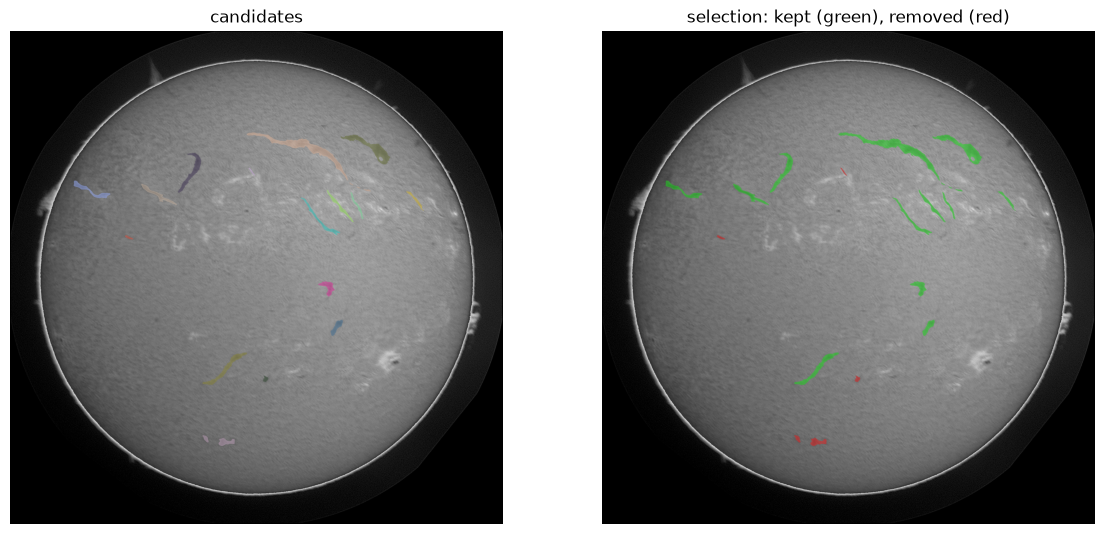

In [7]:
lab, X = score_candidates(prob, img, path, scorer, cnns, cfg)
keep = X.inst.to_numpy()[X.score.to_numpy() > cfg['cnn_cut']]
print(f'candidate settings: {CAND}')
print(f'{len(X)} candidates, {len(keep)} kept')
display(X[['inst', 'area', 'p_mean', 'lgb', 'cnn', 'score']].sort_values('score', ascending=False).round(3))
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(overlay(img, lab, {k: rng.integers(60, 255, 3) for k in X.inst})); ax[0].set_title('candidates')
ax[1].imshow(overlay(img, lab, {k: (40, 220, 40) if k in keep else (230, 40, 40) for k in X.inst}))
ax[1].set_title('selection: kept (green), removed (red)')
for a in ax: a.axis('off')

## 7. All images → submission
The same functions run on every image in `IMAGES`; the kept candidates are written as disjoint COCO RLE masks.

In [8]:
sub = predict_folder(IMAGES, cfg, groups, scorer, cnns)
sub.to_csv(OUT, index=False)
print(len(sub), 'filaments in', sub.filament_id.str.rsplit('_', n=1).str[0].nunique(), 'images ->', OUT)
sub.head()

1/180 5.1 s/image


21/180 5.4 s/image


41/180 5.4 s/image


61/180 5.5 s/image


81/180 5.5 s/image


101/180 5.2 s/image


121/180 5.2 s/image


141/180 5.1 s/image


161/180 5.2 s/image


1114 filaments, 180 images | mean 5.3 s/image
1114 filaments in 176 images -> submission.csv


,filament_id,segmentation_rle
0,20110120105534Ch_1,m_Zi23mo12O001O1O0010O05K0bPNEUo1<hPNHWo1`02N1...
1,20110120105534Ch_2,PkVo12mo11O01Oko51SPJ1O0011N10010O10O101O00000...
2,20110130110334Ch_1,b_jd23lo16K2M2N3N1O5L0001NnPN^Ogn1b0VQNBin1`0R...
3,20110214175414Mh_1,Z]d[25go15M3N2I7M2O2O0O2O0POXOgRNj0Wm1YOgRNg0X...
4,20110214175414Mh_2,^^^d24lo11O0O2O00001O00010O1O001O00000O10O0100...


## 8. Inspect the result
Masks of the example image decoded back from `submission.csv`.

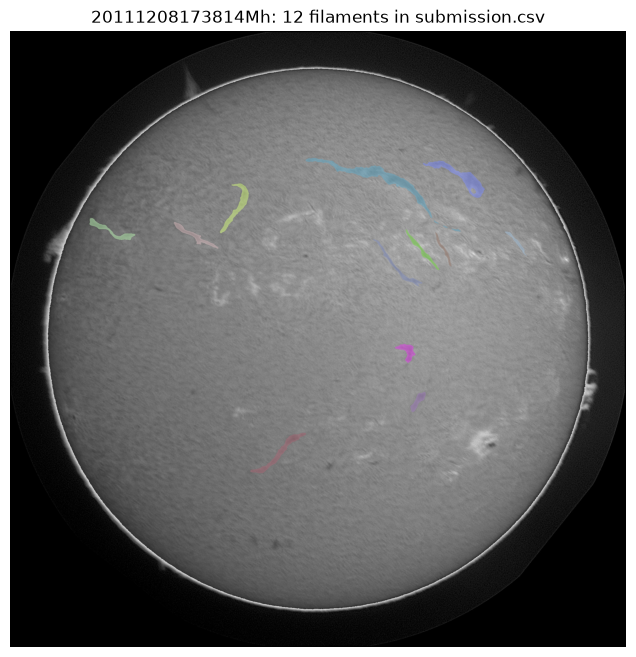

In [9]:
import pandas as pd
import pycocotools.mask as mu
sub = pd.read_csv(OUT)
rows = sub[sub.filament_id.str.rsplit('_', n=1).str[0] == path.stem]
dec = np.zeros(img.shape, np.int32)
for i, c in enumerate(rows.segmentation_rle, 1):
    dec[mu.decode({'size': [2048, 2048], 'counts': c.encode()}).astype(bool)] = i
assert (keep_instances(lab, keep) > 0).sum() == (dec > 0).sum()
plt.figure(figsize=(8, 8)); plt.imshow(overlay(img, dec, {i: rng.integers(60, 255, 3) for i in range(1, len(rows) + 1)}))
plt.axis('off'); plt.title(f'{path.stem}: {len(rows)} filaments in submission.csv');

## 9. Evaluation (out-of-fold, training images)
The test labels are not public, so the pipeline is evaluated on the 707 training images with the competition metric (PQ at IoU > 0.5, every annotator's drawing scored separately and pooled) and the rubric's IoU, Dice, split and merge statistics. Each image is predicted only by the fold-k U-Nets of the two encoders, which did not see it during training (same 5-fold split as in training).

Two rows:
- **all candidates**: segmentation + candidate generation, every candidate kept. Fully out-of-fold.
- **with selector**: plus the bundled LightGBM + CNN selector. The U-Nets are out-of-fold, but the bundled selectors were fitted on the candidates of all training images, so this row is optimistic. The unbiased estimate of the full system is the nested cross-validation of section 2, step 3 (printed by `src/scorer.py` and `src/cnn_selector.py`): **PQ 0.4581** for the stored bundle.

For reference, one annotator scored against the others reaches PQ 0.336.

In [10]:
if EVALUATE:
    import pandas as pd
    from data import TRAIN_IMG, get_folds, gt_frame, load_records
    from infer import select_cnn
    from metric import compute_pq, instances_to_rows, rubric_stats
    from post import prob_to_instances
    records, folds = load_records(), get_folds()
    assert all(r.endswith(f'fold{k}') for runs in cfg['runs'] for k, r in enumerate(runs))
    rows, stems = {'all candidates': [], 'with selector': []}, []
    t0 = time.time()
    for k in range(5):
        fold_groups = [[g[k]] for g in groups]  # fold-k model of each encoder: not trained on these images
        fold_stems = folds.loc[folds.fold == k, 'stem'].tolist()[:EVAL_PER_FOLD]
        stems += fold_stems
        for s in fold_stems:
            p = TRAIN_IMG / f'{s}.jpeg'
            im = read_image(p)
            pr = ensemble_prob(im, fold_groups, cfg['tta'])
            rows['all candidates'] += instances_to_rows(s, prob_to_instances(pr, **CAND))
            rows['with selector'] += instances_to_rows(s, select_cnn(pr, im, p, scorer, cnns, cfg))
        print(f'fold {k} done, {time.time() - t0:.0f} s')
    pred = {n: pd.DataFrame(r, columns=['filament_id', 'segmentation_rle']) for n, r in rows.items()}
    stem_of = lambda df: df.filament_id.str.rsplit('_', n=1).str[0]
    gt = gt_frame(records, stems)
    table = pd.DataFrame({n: {**compute_pq(gt, d), **rubric_stats(gt, d)} for n, d in pred.items()}).T
    fold_of = folds.set_index('stem').fold
    per_fold = pd.DataFrame({n: {f'PQ fold {k}': compute_pq(gt[stem_of(gt).str.split('-', n=1).str[1].map(fold_of) == k],
                                                             d[stem_of(d).map(fold_of) == k])['pq'] for k in range(5)}
                             for n, d in pred.items()}).T
    print(f'{len(stems)} training images, {len(gt)} ground-truth filaments')
    pd.set_option('display.width', 200)
    display(table[['pq', 'sq', 'rq', 'tp', 'fp', 'fn', 'iou_mean', 'dice_mean', 'gt_split', 'pred_merge']].round(4))
    display(per_fold.round(4))

fold 0 done, 203 s


fold 1 done, 406 s


fold 2 done, 609 s


fold 3 done, 816 s


fold 4 done, 1020 s


707 training images, 8199 ground-truth filaments


,pq,sq,rq,tp,fp,fn,iou_mean,dice_mean,gt_split,pred_merge
all candidates,0.4159,0.6782,0.6133,5652.0,4581.0,2547.0,0.5614,0.692,0.0622,0.0239
with selector,0.4697,0.6818,0.6889,5345.0,1974.0,2854.0,0.6039,0.735,0.0261,0.0310


,PQ fold 0,PQ fold 1,PQ fold 2,PQ fold 3,PQ fold 4
all candidates,0.4207,0.4144,0.4180,0.4151,0.4114
with selector,0.4664,0.4691,0.4811,0.4708,0.4615
